# Python EDA and Visualization

In [ ]:
# loading all nine original Olist datasets
import pandas as pd

file_paths = {
    "orders": "/content/drive/MyDrive/oilst_data/olist_orders_dataset.csv",
    "customers": "/content/drive/MyDrive/oilst_data/olist_customers_dataset.csv",
    "order_items": "/content/drive/MyDrive/oilst_data/olist_order_items_dataset.csv",
    "payments": "/content/drive/MyDrive/oilst_data/olist_order_payments_dataset.csv",
    "reviews": "/content/drive/MyDrive/oilst_data/olist_order_reviews_dataset.csv",
    "products": "/content/drive/MyDrive/oilst_data/olist_products_dataset.csv",
    "sellers": "/content/drive/MyDrive/oilst_data/olist_sellers_dataset.csv",
    "geolocation": "/content/drive/MyDrive/oilst_data/olist_geolocation_dataset.csv",
    "category_translation": "/content/drive/MyDrive/oilst_data/product_category_name_translation.csv"
}

dataframes = {
    name: pd.read_csv(path)
    for name, path in file_paths.items()
}

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
for name, df in dataframes.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

orders: 99,441 rows, 8 columns
customers: 99,441 rows, 5 columns
order_items: 112,650 rows, 7 columns
payments: 103,886 rows, 5 columns
reviews: 99,224 rows, 7 columns
products: 32,951 rows, 9 columns
sellers: 3,095 rows, 4 columns
geolocation: 1,000,163 rows, 5 columns
category_translation: 71 rows, 2 columns


In [ ]:
for name, df in dataframes.items():
    print(f"\n--- {name.upper()} ---")
    print("Missing values:", df.isnull().sum().sum())
    print("Columns with missing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])


--- ORDERS ---
Missing values: 4908
Columns with missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

--- CUSTOMERS ---
Missing values: 0
Columns with missing values:
Series([], dtype: int64)

--- ORDER_ITEMS ---
Missing values: 0
Columns with missing values:
Series([], dtype: int64)

--- PAYMENTS ---
Missing values: 0
Columns with missing values:
Series([], dtype: int64)

--- REVIEWS ---
Missing values: 145903
Columns with missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64

--- PRODUCTS ---
Missing values: 2448
Columns with missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

--- SELLERS ---
Missing values: 0

In [ ]:
date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

for dataset, columns in date_columns.items():
    for column in columns:
        dataframes[dataset][column] = pd.to_datetime(
            dataframes[dataset][column],
            errors="coerce"
        )

print("Date conversion completed.")
print(dataframes["orders"].dtypes)

Date conversion completed.
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [ ]:
numeric_columns = {
    "order_items": ["price", "freight_value"],
    "payments": ["payment_value", "payment_installments"],
    "reviews": ["review_score"],
    "products": [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
}

for dataset, columns in numeric_columns.items():
    print(f"\n--- {dataset.upper()} ---")
    print(dataframes[dataset][columns].dtypes)


--- ORDER_ITEMS ---
price            float64
freight_value    float64
dtype: object

--- PAYMENTS ---
payment_value           float64
payment_installments      int64
dtype: object

--- REVIEWS ---
review_score    int64
dtype: object

--- PRODUCTS ---
product_weight_g     float64
product_length_cm    float64
product_height_cm    float64
product_width_cm     float64
dtype: object


In [ ]:
analysis_data = {
    name: df.copy()
    for name, df in dataframes.items()
}

print("Analytical copies created:", len(analysis_data))

Analytical copies created: 9


In [ ]:
# How have monthly delivered orders, merchandise sales and AOV changed over time?
monthly_orders = (
    analysis_data["orders"]
    .query("order_status == 'delivered'")
    [["order_id", "order_purchase_timestamp"]]
)

monthly_items = (
    analysis_data["order_items"]
    .groupby("order_id", as_index=False)
    .agg(merchandise_sales=("price", "sum"))
)

monthly_performance = monthly_orders.merge(
    monthly_items,
    on="order_id",
    how="inner"
)

monthly_performance["year_month"] = (
    monthly_performance["order_purchase_timestamp"].dt.to_period("M")
)

monthly_performance = (
    monthly_performance.groupby("year_month")
    .agg(
        delivered_orders=("order_id", "nunique"),
        merchandise_sales=("merchandise_sales", "sum")
    )
    .reset_index()
)

monthly_performance["AOV"] = (
    monthly_performance["merchandise_sales"] /
    monthly_performance["delivered_orders"]
)

print(monthly_performance.to_string(index=False))

year_month  delivered_orders  merchandise_sales        AOV
   2016-09                 1             134.97 134.970000
   2016-10               265           40325.11 152.170226
   2016-12                 1              10.90  10.900000
   2017-01               750          111798.36 149.064480
   2017-02              1653          234223.40 141.695947
   2017-03              2546          359198.85 141.083602
   2017-04              2303          340669.68 147.924307
   2017-05              3546          489338.25 137.997250
   2017-06              3135          421923.37 134.584807
   2017-07              3872          481604.52 124.381333
   2017-08              4193          554699.70 132.291844
   2017-09              4150          607399.67 146.361366
   2017-10              4478          648247.65 144.762762
   2017-11              7289          987765.37 135.514525
   2017-12              5513          726033.19 131.694756
   2018-01              7069          924645.00 130.8028

In [ ]:
# How many unique customers made one purchase versus repeat purchases?
customer_orders = (
    analysis_data["orders"]
    .query("order_status == 'delivered'")
    .merge(
        analysis_data["customers"][["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

customer_segments = (
    customer_orders.value_counts()
    .rename_axis("order_frequency")
    .reset_index(name="customer_count")
)

customer_segments["segment"] = np.where(
    customer_segments["order_frequency"] == 1,
    "One-time",
    "Repeat"
)

print(customer_segments)

   order_frequency  customer_count   segment
0                1           90557  One-time
1                2            2573    Repeat
2                3             181    Repeat
3                4              28    Repeat
4                5               9    Repeat
5                6               5    Repeat
6                7               3    Repeat
7                9               1    Repeat
8               15               1    Repeat


In [ ]:
# How is merchandise value distributed across delivered orders?
order_value = (
    analysis_data["order_items"]
    .groupby("order_id", as_index=False)
    .agg(order_value=("price", "sum"))
)

delivered_ids = analysis_data["orders"].loc[
    analysis_data["orders"]["order_status"] == "delivered",
    "order_id"
]

order_value = order_value[
    order_value["order_id"].isin(delivered_ids)
]

print(order_value["order_value"].describe().round(2))

count    96478.00
mean       137.04
std        209.05
min          0.85
25%         45.90
50%         86.57
75%        149.90
max      13440.00
Name: order_value, dtype: float64


In [ ]:
# How many delivered orders are above the IQR upper outlier threshold?
Q1 = order_value["order_value"].quantile(0.25)
Q3 = order_value["order_value"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = order_value[
    order_value["order_value"] > upper_bound
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Upper outlier threshold:", round(upper_bound, 2))
print("Potential high-value outliers:", len(outliers))
print("Percentage of orders:", round(len(outliers) / len(order_value) * 100, 2), "%")

Q1: 45.9
Q3: 149.9
IQR: 104.0
Upper outlier threshold: 305.9
Potential high-value outliers: 7659
Percentage of orders: 7.94 %


In [ ]:
# How strongly skewed and heavy tailed is the delivered order value distribution?
print("Skewness:", round(order_value["order_value"].skew(), 2))
print("Kurtosis:", round(order_value["order_value"].kurt(), 2))

Skewness: 9.89
Kurtosis: 277.01


In [ ]:
# How does freight compare with merchandise value across delivered orders?
order_freight = (
    analysis_data["order_items"]
    .groupby("order_id", as_index=False)
    .agg(
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)

order_freight = order_freight[
    order_freight["order_id"].isin(delivered_ids)
].copy()

order_freight["freight_ratio"] = (
    order_freight["freight_value"] /
    order_freight["merchandise_value"]
)

print(order_freight[["merchandise_value", "freight_value", "freight_ratio"]].describe().round(2))

       merchandise_value  freight_value  freight_ratio
count           96478.00       96478.00       96478.00
mean              137.04          22.79           0.31
std               209.05          21.56           0.31
min                 0.85           0.00           0.00
25%                45.90          13.85           0.13
50%                86.57          17.17           0.22
75%               149.90          24.02           0.38
max             13440.00        1794.96          21.45


In [ ]:
# How many delivered orders have freight costs greater than merchandise value?
high_freight = order_freight[
    order_freight["freight_ratio"] > 1
]

print("Orders with freight above merchandise value:", len(high_freight))
print("Percentage of delivered orders:", round(len(high_freight) / len(order_freight) * 100, 2), "%")
print("Average merchandise value:", round(high_freight["merchandise_value"].mean(), 2))
print("Average freight value:", round(high_freight["freight_value"].mean(), 2))

Orders with freight above merchandise value: 3075
Percentage of delivered orders: 3.19 %
Average merchandise value: 21.34
Average freight value: 29.27


In [ ]:
# What is the distribution of customer review scores?
print(
    analysis_data["reviews"]["review_score"]
    .value_counts()
    .sort_index()
)

print("\nPercentage distribution:")
print(
    (analysis_data["reviews"]["review_score"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Percentage distribution:
review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: proportion, dtype: float64


In [ ]:
# Measure each customer's recency, purchase frequency and merchandise value
delivered_orders = analysis_data["orders"].loc[
    analysis_data["orders"]["order_status"] == "delivered",
    ["order_id", "customer_id", "order_purchase_timestamp"]
].copy()

delivered_orders = delivered_orders.merge(
    analysis_data["customers"][["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

delivered_orders = delivered_orders.merge(
    order_value[["order_id", "order_value"]],
    on="order_id",
    how="left"
)

reference_date = delivered_orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = delivered_orders.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (reference_date - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum")
).reset_index()

print(rfm.describe().round(2))
print("\nCustomer records:", len(rfm))

        recency  frequency  monetary
count  93358.00   93358.00  93358.00
mean     237.94       1.03    141.62
std      152.59       0.21    215.69
min        1.00       1.00      0.85
25%      114.00       1.00     47.65
50%      219.00       1.00     89.73
75%      346.00       1.00    154.74
max      714.00      15.00  13440.00

Customer records: 93358


In [ ]:
# Reduce RFM skewness before customer clustering
rfm_model = rfm[["recency", "frequency", "monetary"]].copy()

rfm_model["frequency"] = np.log1p(rfm_model["frequency"])
rfm_model["monetary"] = np.log1p(rfm_model["monetary"])

print("Skewness after transformation:")
print(rfm_model.skew().round(2))

Skewness after transformation:
recency      0.45
frequency    6.52
monetary     0.28
dtype: float64


In [ ]:
# putting all RFM features on a comparable scale for clustering
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_model)

print("Scaled data shape:", rfm_scaled.shape)
print("Feature means:", rfm_scaled.mean(axis=0).round(2))
print("Feature standard deviations:", rfm_scaled.std(axis=0).round(2))

Scaled data shape: (93358, 3)
Feature means: [-0. -0.  0.]
Feature standard deviations: [1. 1. 1.]


In [ ]:
# Number of RFM clusters produces the best separation
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(
        rfm_scaled, labels,
        sample_size=10000,
        random_state=42
    )
    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

Clusters: 2, Silhouette Score: 0.7054
Clusters: 3, Silhouette Score: 0.3578
Clusters: 4, Silhouette Score: 0.3682
Clusters: 5, Silhouette Score: 0.3443
Clusters: 6, Silhouette Score: 0.3396


In [ ]:
# RFM cluster
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
rfm["cluster"] = kmeans.fit_predict(rfm_scaled)

cluster_profile = rfm.groupby("cluster").agg(
    customers=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    median_monetary=("monetary", "median")
).round(2)

cluster_profile["customer_percentage"] = (
    cluster_profile["customers"] / len(rfm) * 100
).round(2)

print(cluster_profile)

         customers  avg_recency  avg_frequency  avg_monetary  median_monetary  \
cluster                                                                         
0             2801       220.29           2.11        260.05           182.10   
1            90557       238.49           1.00        137.96            86.96   

         customer_percentage  
cluster                       
0                        3.0  
1                       97.0  


In [ ]:
# Merge delivery performance data with customer review scores for statistical analysis
delivery_reviews = analysis_data["reviews"].merge(
    analysis_data["orders"][["order_id", "order_status", "order_delivered_customer_date",
                             "order_estimated_delivery_date"]],
    on="order_id",
    how="inner"
)

delivery_reviews = delivery_reviews[
    (delivery_reviews["order_status"] == "delivered") &
    delivery_reviews["order_delivered_customer_date"].notna() &
    delivery_reviews["order_estimated_delivery_date"].notna()
].copy()

delivery_reviews["delivery_status"] = np.where(
    delivery_reviews["order_delivered_customer_date"] >
    delivery_reviews["order_estimated_delivery_date"],
    "Late",
    "On Time"
)

print(delivery_reviews["delivery_status"].value_counts())
print("\nReview records:", len(delivery_reviews))
print("\nAverage review score:")
print(delivery_reviews.groupby("delivery_status")["review_score"].mean().round(2))

delivery_status
On Time    88653
Late        7700
Name: count, dtype: int64

Review records: 96353

Average review score:
delivery_status
Late       2.57
On Time    4.29
Name: review_score, dtype: float64


In [ ]:
# Compare historical customer value between one time and repeat purchasers
one_time = rfm.loc[rfm["frequency"] == 1, "monetary"]
repeat = rfm.loc[rfm["frequency"] > 1, "monetary"]

print("One-time customers:", len(one_time))
print("Repeat customers:", len(repeat))
print("One-time median value:", round(one_time.median(), 2))
print("Repeat median value:", round(repeat.median(), 2))

One-time customers: 90557
Repeat customers: 2801
One-time median value: 86.96
Repeat median value: 182.1


In [ ]:
# Perform a Mann Whitney U test to assess differences in historical merchandise value between one time and repeat customers
from scipy.stats import mannwhitneyu

u_stat, p_value = mannwhitneyu(
    repeat,
    one_time,
    alternative="two-sided"
)

print("U statistic:", u_stat)
print("P-value:", p_value)

U statistic: 189530202.0
P-value: 0.0


In [ ]:
# Quantify the difference in historical monetary value between repeat and one time purchasers using rank biserial correlation
n_repeat = len(repeat)
n_one_time = len(one_time)

rank_biserial = (2 * u_stat) / (n_repeat * n_one_time) - 1

print("Rank-biserial correlation:", round(rank_biserial, 4))

Rank-biserial correlation: 0.4944


In [ ]:
# Analyze merchandise value across product categories within delivered orders
category_orders = analysis_data["order_items"].merge(
    analysis_data["products"][["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_orders = category_orders.merge(
    delivered_orders[["order_id"]],
    on="order_id",
    how="inner"
)

category_orders["product_category_name"] = (
    category_orders["product_category_name"].fillna("Unknown")
)

category_value = category_orders.groupby(
    ["order_id", "product_category_name"]
).agg(
    category_order_value=("price", "sum")
).reset_index()

print("Order-category records:", len(category_value))
print("Categories:", category_value["product_category_name"].nunique())
print(category_value.head())

Order-category records: 97276
Categories: 74
                           order_id product_category_name  \
0  00010242fe8c5a6d1ba2dd792cb16214            cool_stuff   
1  00018f77f2f0320c557190d7a144bdd3              pet_shop   
2  000229ec398224ef6ca0657da4fc703e      moveis_decoracao   
3  00024acbcdf0a6daa1e931b038114c75            perfumaria   
4  00042b26cf59d7ce69dfabb4e55b4fd9    ferramentas_jardim   

   category_order_value  
0                 58.90  
1                239.90  
2                199.00  
3                 12.99  
4                199.90  


In [ ]:
# Evaluate order level sample sizes and merchandise value statistics across product categories to identify categories suitable for reliable comparison
category_sample = category_value.groupby("product_category_name").agg(
    order_count=("order_id", "nunique"),
    median_value=("category_order_value", "median"),
    mean_value=("category_order_value", "mean")
).sort_values("order_count", ascending=False)

print(category_sample)

                                               order_count  median_value  \
product_category_name                                                      
cama_mesa_banho                                       9272        88.000   
beleza_saude                                          8647        85.000   
esporte_lazer                                         7530        89.900   
informatica_acessorios                                6530        86.000   
moveis_decoracao                                      6307        79.900   
...                                                    ...           ...   
portateis_cozinha_e_preparadores_de_alimentos           13        35.060   
cds_dvds_musicais                                       12        65.000   
fashion_roupa_infanto_juvenil                            7        89.990   
pc_gamer                                                 7       129.990   
seguros_e_servicos                                       2       141.645   

           

In [ ]:
import seaborn as sns

In [ ]:
# Configure a consistent professional visualisation style.
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.family": "DejaVu Sans",
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("Professional visualisation style applied.")

Professional visualisation style applied.


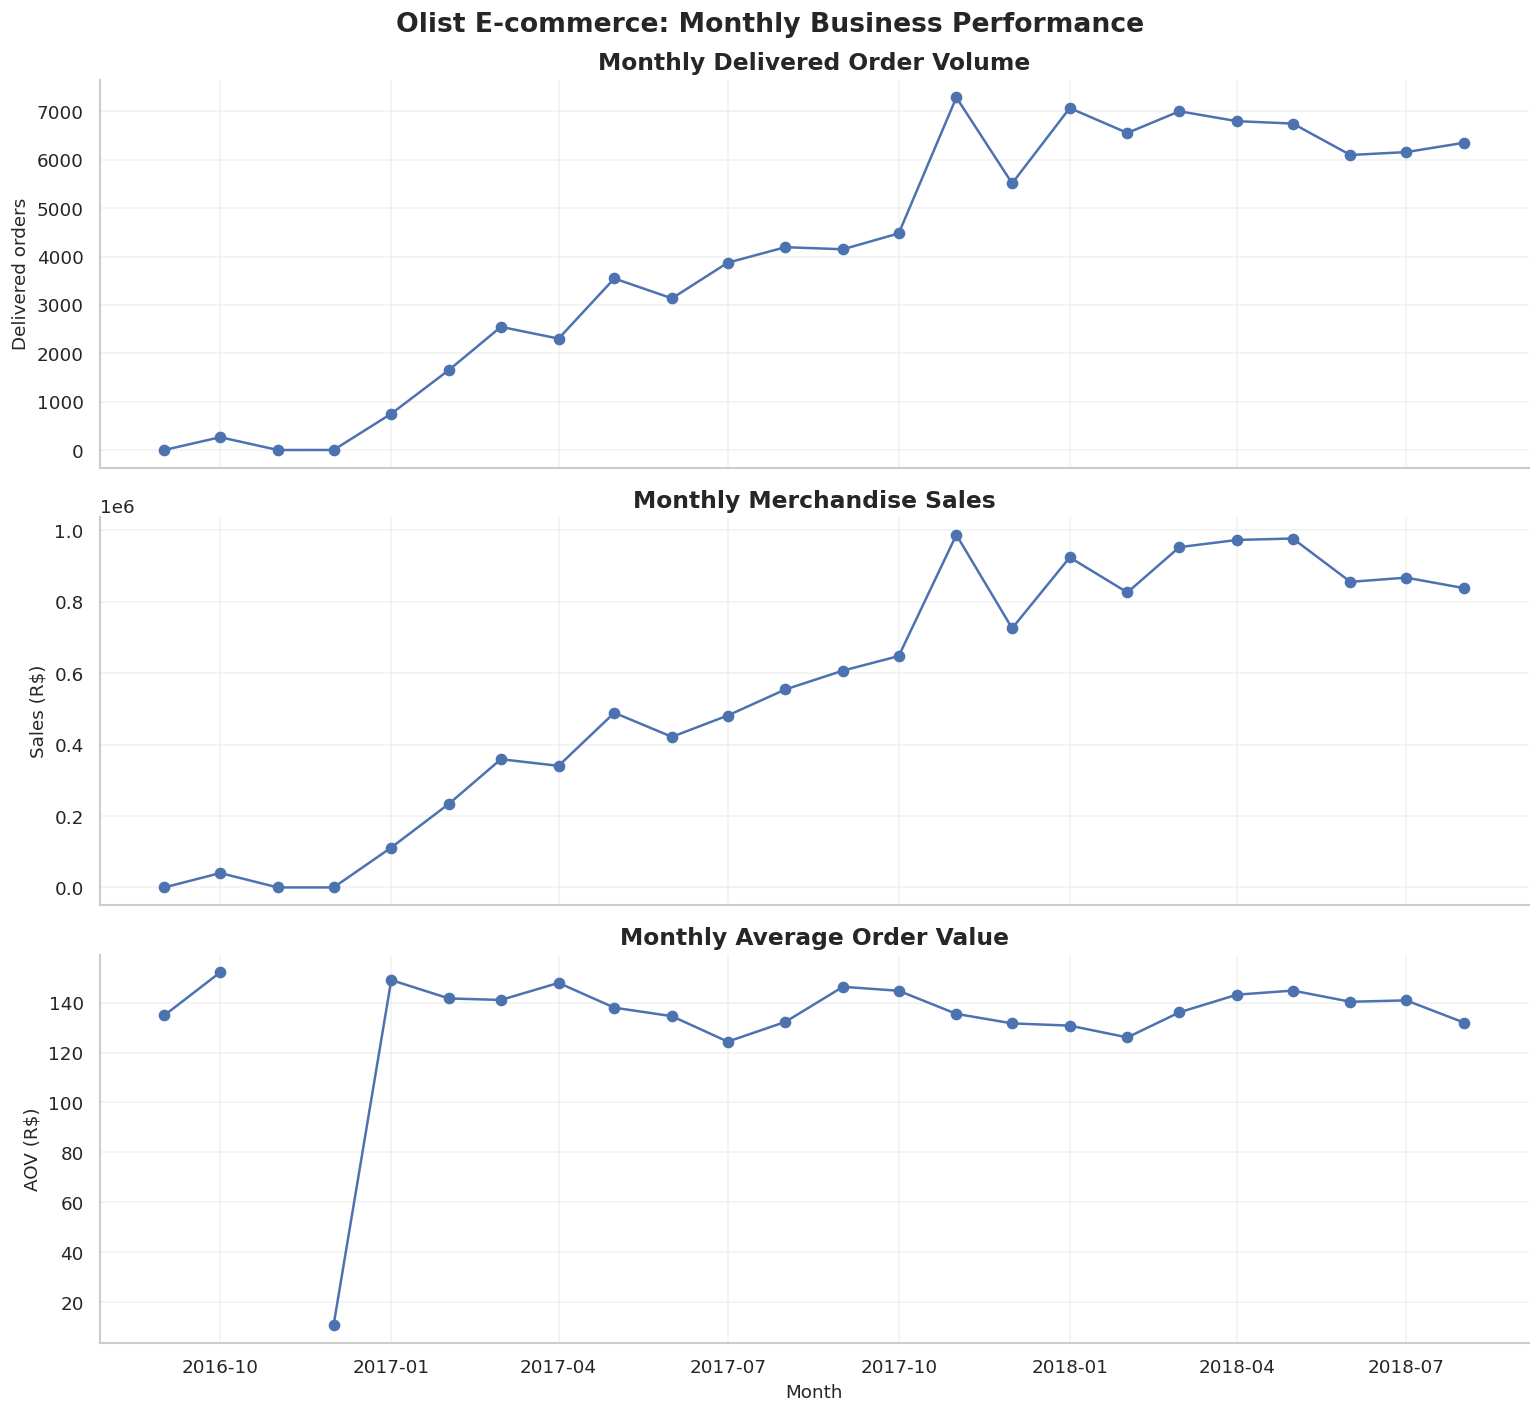

In [ ]:
# Build and visualise monthly business performance from delivered orders.
monthly_chart = (
    delivered_orders
    .groupby(pd.Grouper(key="order_purchase_timestamp", freq="MS"))
    .agg(
        delivered_orders=("order_id", "nunique"),
        merchandise_sales=("order_value", "sum")
    )
    .reset_index()
)

monthly_chart["aov"] = (
    monthly_chart["merchandise_sales"] / monthly_chart["delivered_orders"]
)

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)

axes[0].plot(monthly_chart["order_purchase_timestamp"], monthly_chart["delivered_orders"], marker="o")
axes[0].set_title("Monthly Delivered Order Volume")
axes[0].set_ylabel("Delivered orders")

axes[1].plot(monthly_chart["order_purchase_timestamp"], monthly_chart["merchandise_sales"], marker="o")
axes[1].set_title("Monthly Merchandise Sales")
axes[1].set_ylabel("Sales (R$)")

axes[2].plot(monthly_chart["order_purchase_timestamp"], monthly_chart["aov"], marker="o")
axes[2].set_title("Monthly Average Order Value")
axes[2].set_ylabel("AOV (R$)")
axes[2].set_xlabel("Month")

plt.suptitle("Olist E-commerce: Monthly Business Performance", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

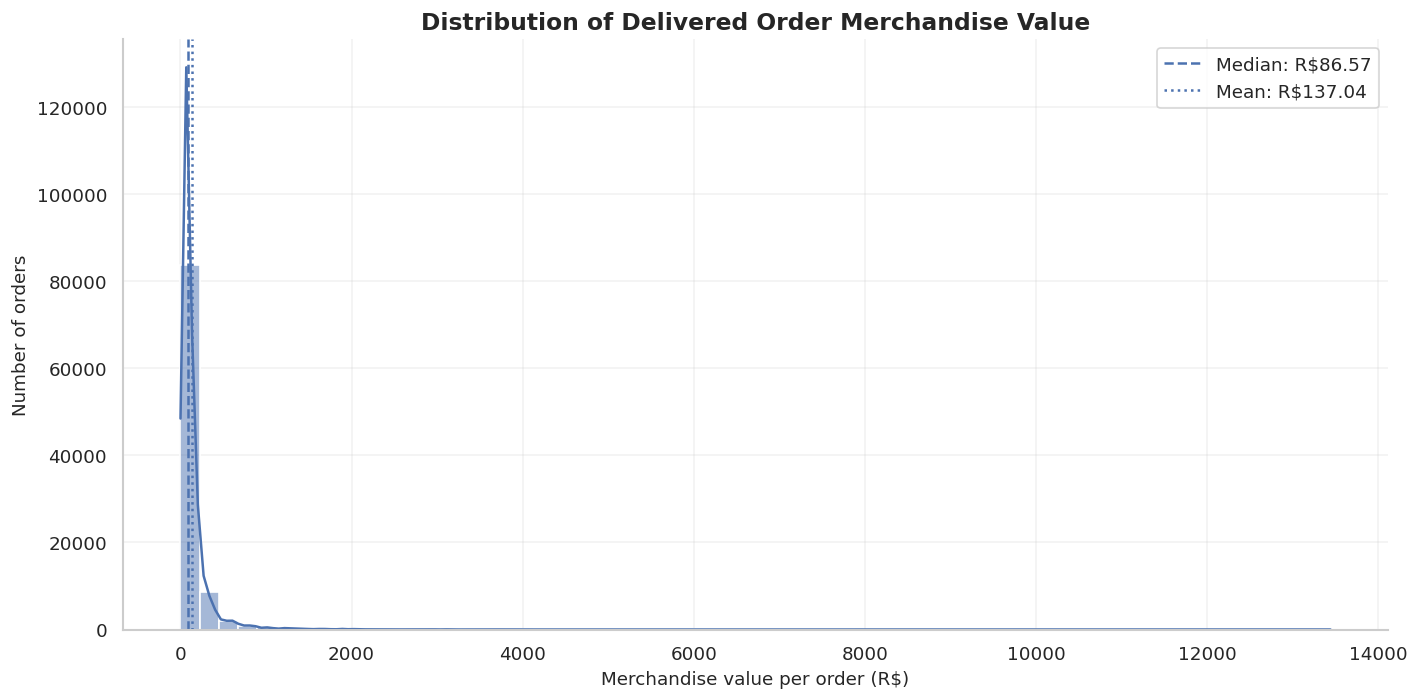

In [ ]:
# Visualise the distribution of merchandise value per delivered order.
plt.figure(figsize=(12, 6))

sns.histplot(
    data=order_value,
    x="order_value",
    bins=60,
    kde=True
)

plt.axvline(
    order_value["order_value"].median(),
    linestyle="--",
    label=f'Median: R${order_value["order_value"].median():,.2f}'
)

plt.axvline(
    order_value["order_value"].mean(),
    linestyle=":",
    label=f'Mean: R${order_value["order_value"].mean():,.2f}'
)

plt.title("Distribution of Delivered Order Merchandise Value")
plt.xlabel("Merchandise value per order (R$)")
plt.ylabel("Number of orders")
plt.legend()
plt.tight_layout()
plt.show()

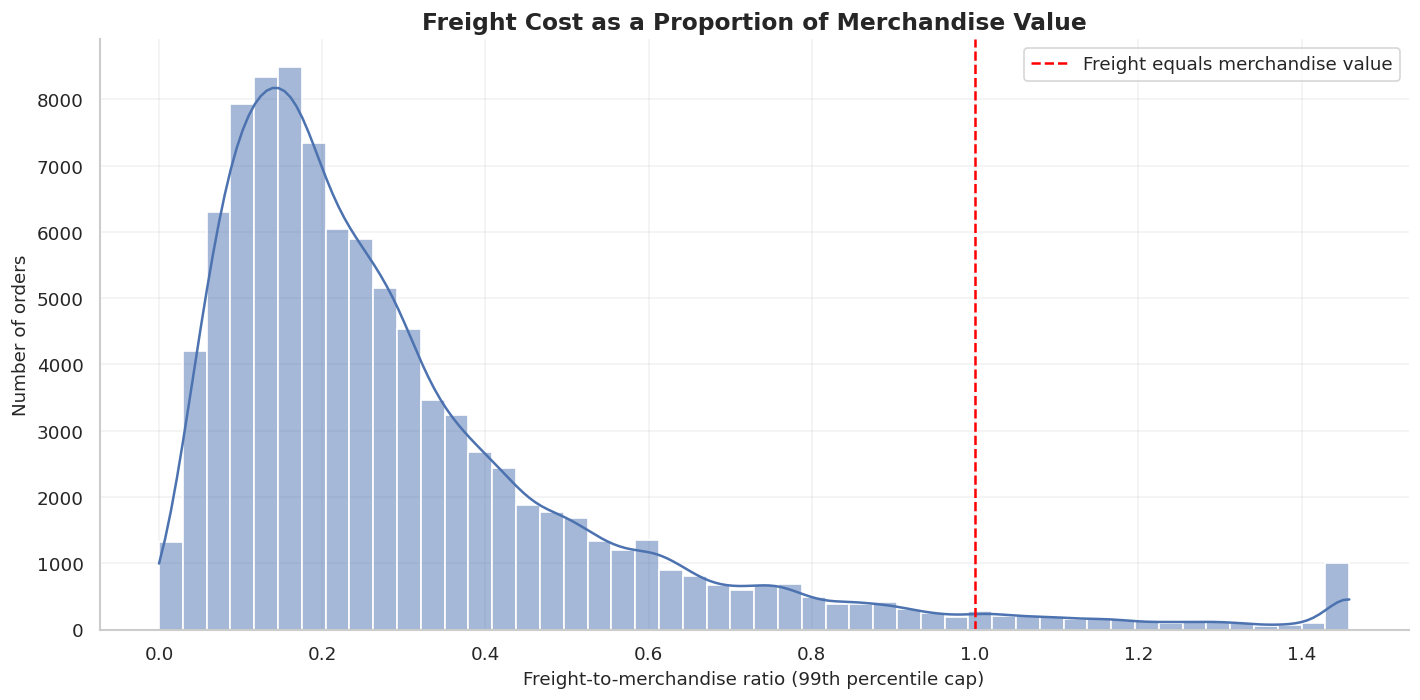

In [ ]:
# Compare freight charges with merchandise value across delivered orders.
freight_chart = order_freight.copy()

freight_chart["freight_ratio_capped"] = freight_chart["freight_ratio"].clip(
    upper=freight_chart["freight_ratio"].quantile(0.99)
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=freight_chart,
    x="freight_ratio_capped",
    bins=50,
    kde=True
)

plt.axvline(1, color="red", linestyle="--", label="Freight equals merchandise value")

plt.title("Freight Cost as a Proportion of Merchandise Value")
plt.xlabel("Freight-to-merchandise ratio (99th percentile cap)")
plt.ylabel("Number of orders")
plt.legend()
plt.tight_layout()
plt.show()

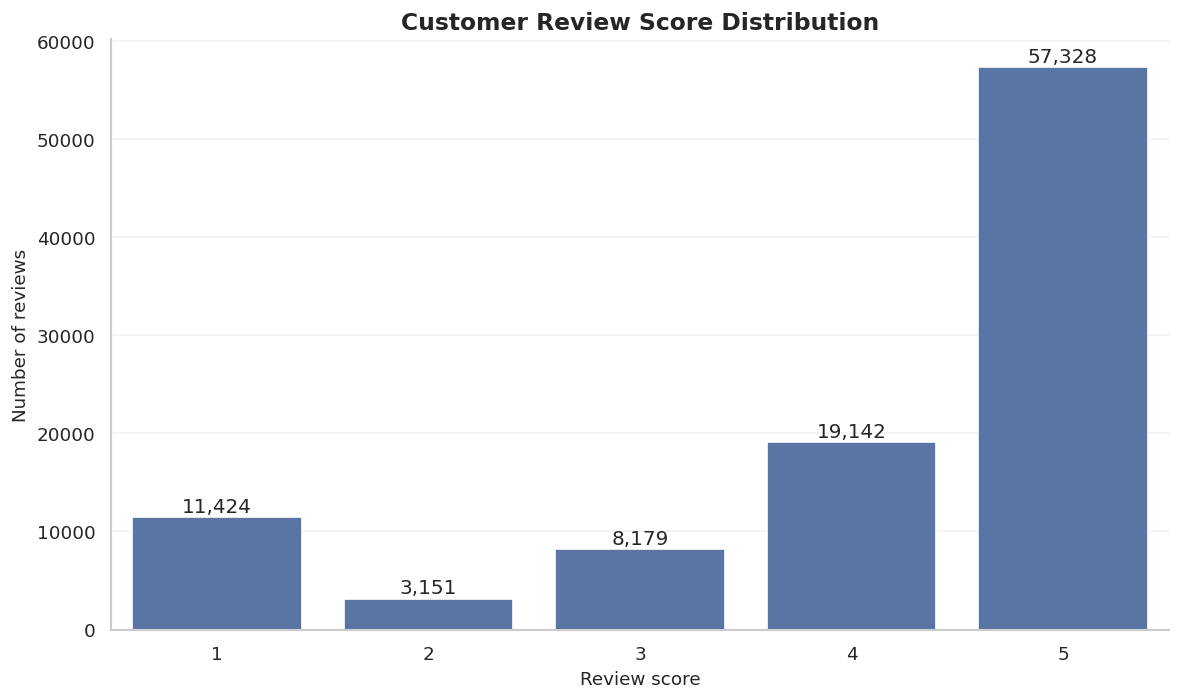

In [ ]:
# Visualise the distribution of customer review scores.
review_counts = (
    analysis_data["reviews"]["review_score"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=review_counts.index,
    y=review_counts.values
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review score")
plt.ylabel("Number of reviews")

for index, value in enumerate(review_counts.values):
    plt.text(index, value + 500, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

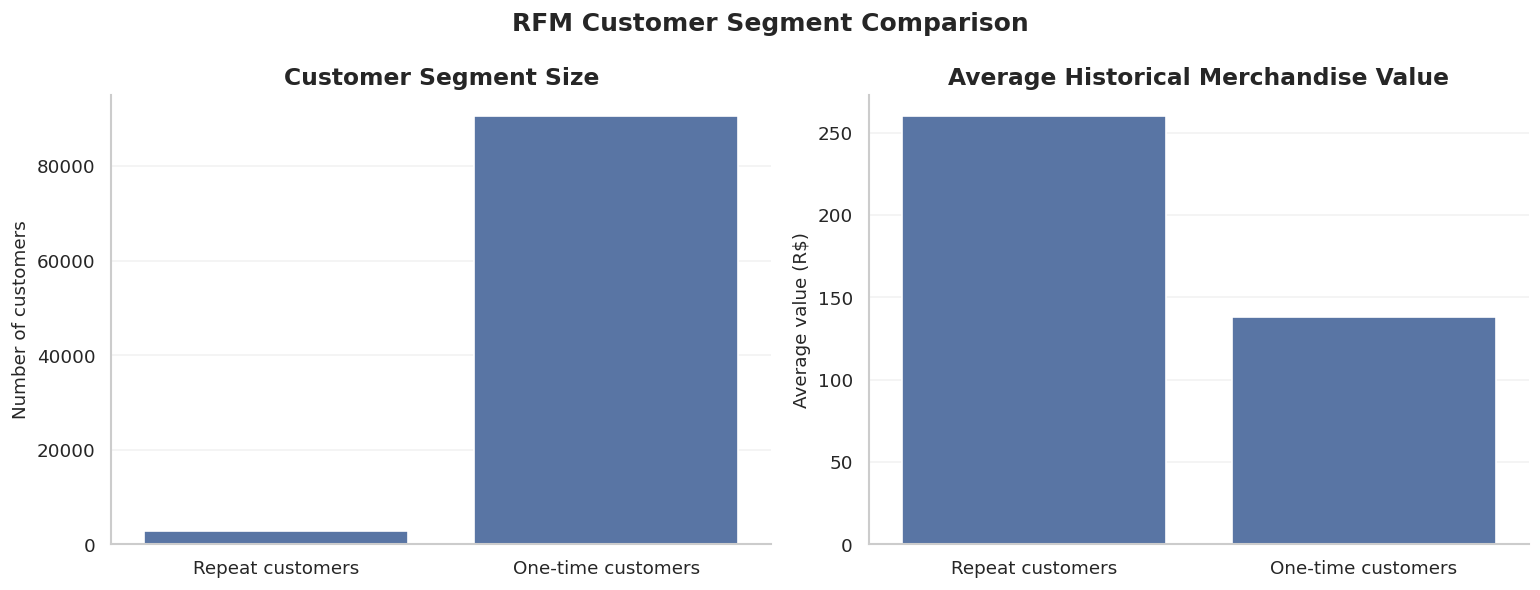

              segment  customers  average_orders  average_value
0    Repeat customers       2801        2.113888     260.053106
1  One-time customers      90557        1.000000     137.958295


In [ ]:
# Compare customer segment size and average historical merchandise value.
segment_data = (
    rfm.groupby("cluster")
    .agg(
        customers=("customer_unique_id", "count"),
        average_orders=("frequency", "mean"),
        average_value=("monetary", "mean")
    )
    .reset_index()
)

segment_data["segment"] = segment_data["cluster"].map({
    0: "Repeat customers",
    1: "One-time customers"
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=segment_data, x="segment", y="customers", ax=axes[0])
axes[0].set_title("Customer Segment Size")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of customers")

sns.barplot(data=segment_data, x="segment", y="average_value", ax=axes[1])
axes[1].set_title("Average Historical Merchandise Value")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average value (R$)")

plt.suptitle("RFM Customer Segment Comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

print(segment_data[["segment", "customers", "average_orders", "average_value"]])

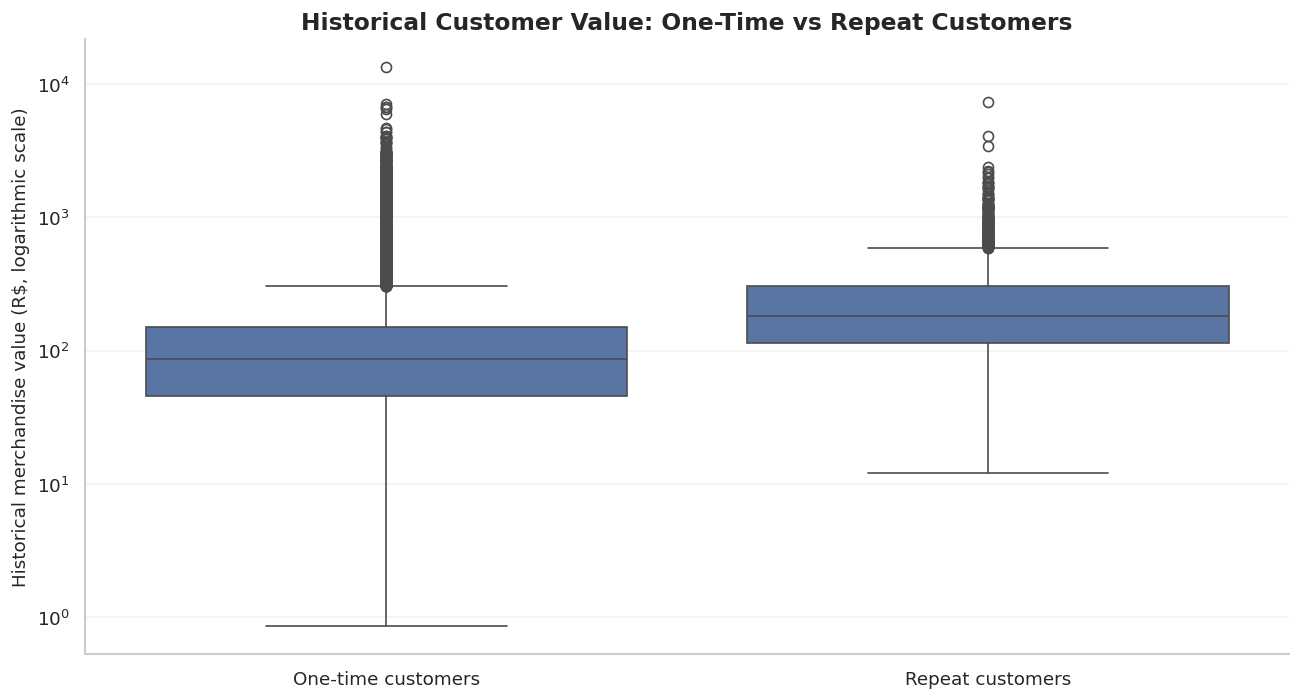

Mann-Whitney U statistic: 189530202.0
P-value: 0.0
Rank-biserial effect size: 0.4944


In [ ]:
# Compare historical merchandise value distributions by customer purchase frequency.
value_comparison = rfm.copy()

value_comparison["segment"] = np.where(
    value_comparison["frequency"] == 1,
    "One-time customers",
    "Repeat customers"
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=value_comparison,
    x="segment",
    y="monetary"
)

plt.yscale("log")
plt.title("Historical Customer Value: One-Time vs Repeat Customers")
plt.xlabel("")
plt.ylabel("Historical merchandise value (R$, logarithmic scale)")
plt.tight_layout()
plt.show()

print("Mann-Whitney U statistic:", u_stat)
print("P-value:", p_value)
print("Rank-biserial effect size:", round(rank_biserial, 4))

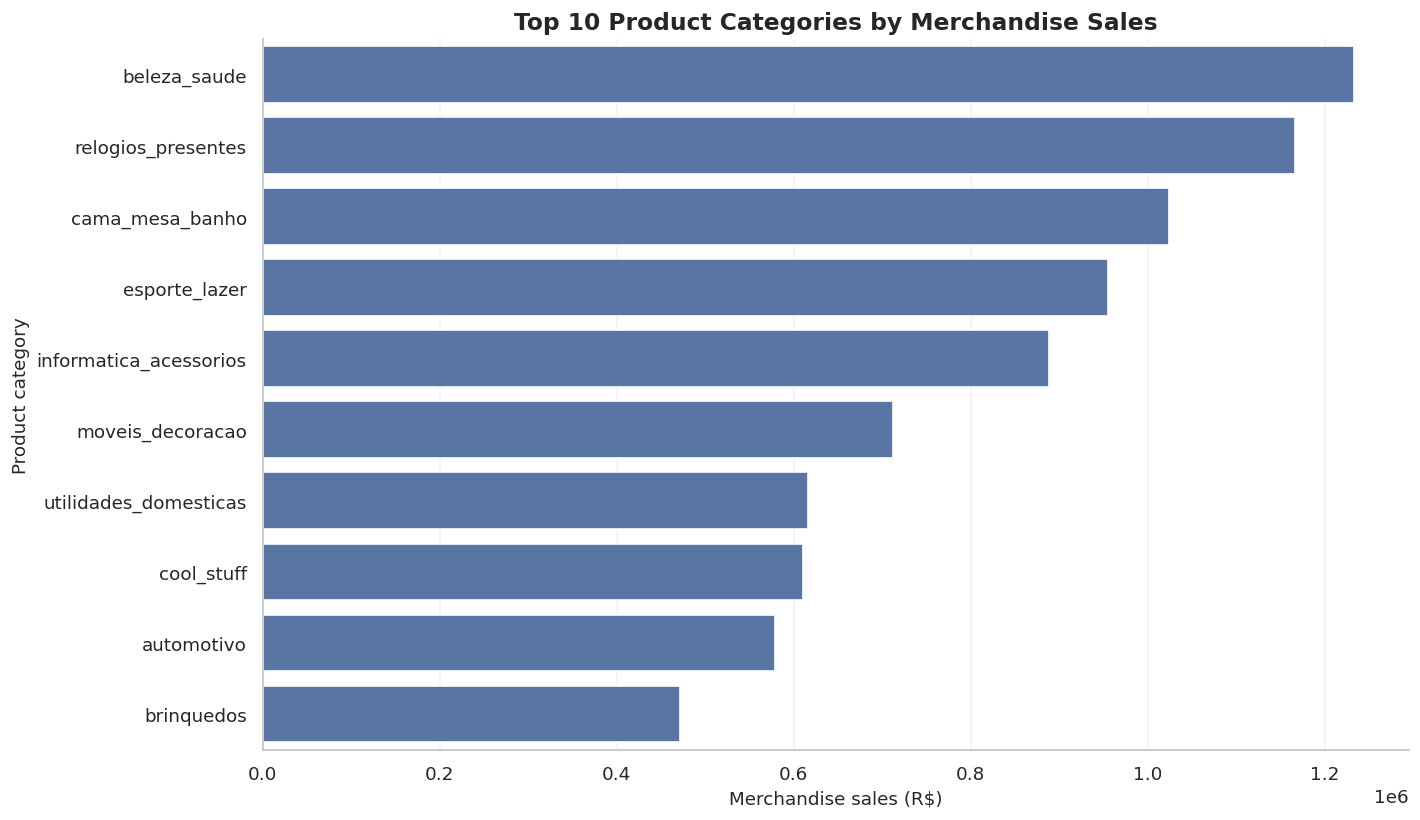

    product_category_name  merchandise_sales  order_volume  items_sold  \
0            beleza_saude         1233131.72          8647        9465   
1      relogios_presentes         1166176.98          5495        5859   
2         cama_mesa_banho         1023434.76          9272       10953   
3           esporte_lazer          954852.55          7530        8431   
4  informatica_acessorios          888724.61          6530        7644   
5        moveis_decoracao          711927.69          6307        8160   
6   utilidades_domesticas          615628.69          5743        6795   
7              cool_stuff          610204.10          3559        3718   
8              automotivo          578966.65          3810        4140   
9              brinquedos          471286.48          3804        4030   

   average_item_value  
0              130.28  
1              199.04  
2               93.44  
3              113.25  
4              116.26  
5               87.25  
6               9

In [ ]:
# Analyse and visualise the top 10 product categories by delivered merchandise sales.
category_chart_data = (
    analysis_data["order_items"]
    .merge(
        analysis_data["products"][["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .merge(
        analysis_data["orders"][["order_id", "order_status"]],
        on="order_id",
        how="inner"
    )
)

category_chart_data = category_chart_data[
    category_chart_data["order_status"] == "delivered"
].copy()

category_chart_data["product_category_name"] = (
    category_chart_data["product_category_name"].fillna("Unknown")
)

category_performance = (
    category_chart_data
    .groupby("product_category_name")
    .agg(
        merchandise_sales=("price", "sum"),
        order_volume=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        average_item_value=("price", "mean")
    )
    .sort_values("merchandise_sales", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_performance,
    x="merchandise_sales",
    y="product_category_name"
)

plt.title("Top 10 Product Categories by Merchandise Sales")
plt.xlabel("Merchandise sales (R$)")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

print(category_performance.round(2))

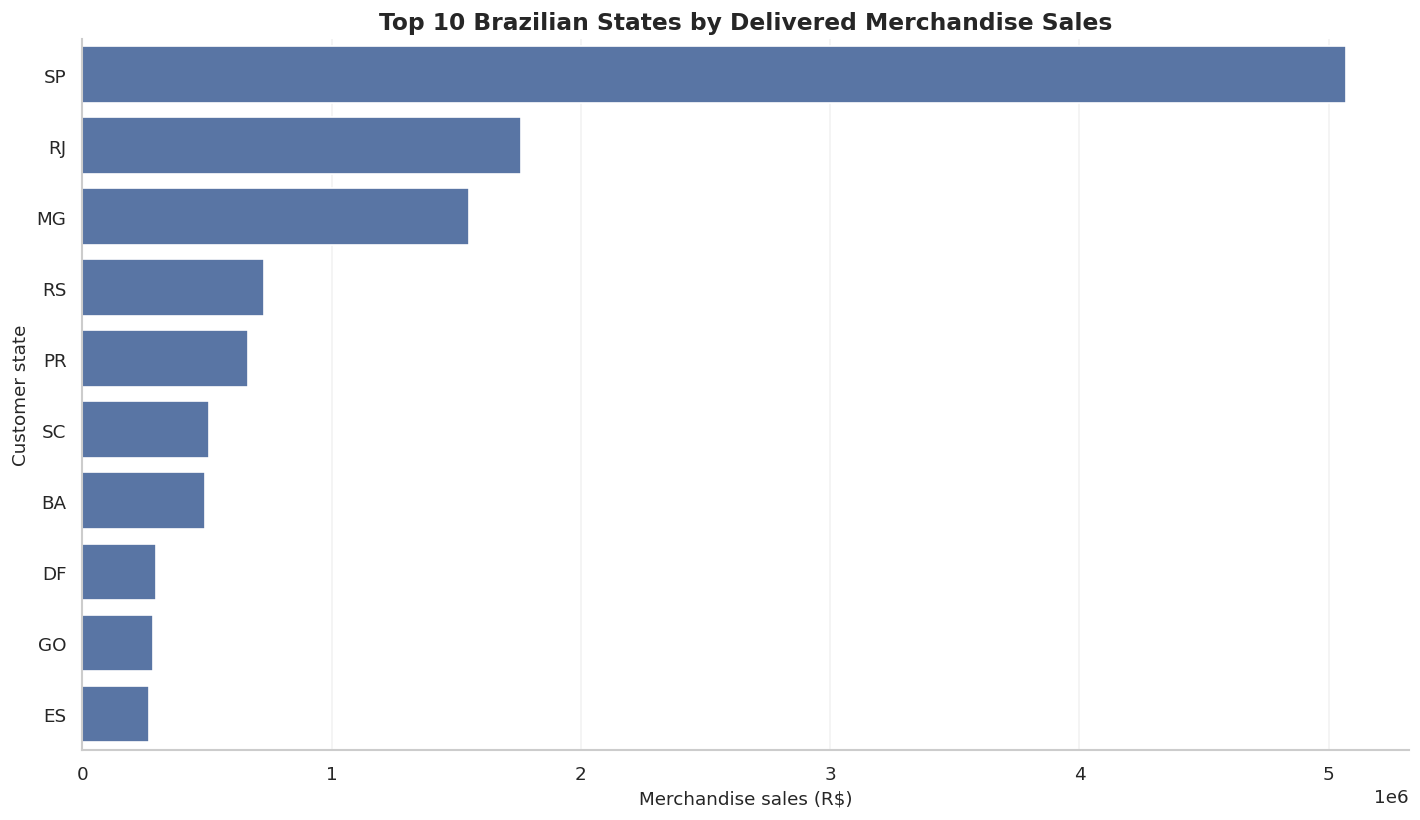

  customer_state  merchandise_sales  delivered_orders  purchasing_customers
0             SP         5067633.16             40501                 40501
1             RJ         1759651.13             12350                 12350
2             MG         1552481.83             11354                 11354
3             RS          728897.47              5345                  5345
4             PR          666063.51              4923                  4923
5             SC          507012.13              3546                  3546
6             BA          493584.14              3256                  3256
7             DF          296498.41              2080                  2080
8             GO          282836.70              1957                  1957
9             ES          268643.45              1995                  1995


In [ ]:
# Analyse and visualise delivered merchandise sales by customer state.
state_chart_data = (
    analysis_data["orders"]
    .merge(
        analysis_data["customers"][["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .merge(
        order_value[["order_id", "order_value"]],
        on="order_id",
        how="inner"
    )
)

state_performance = (
    state_chart_data[state_chart_data["order_status"] == "delivered"]
    .groupby("customer_state")
    .agg(
        merchandise_sales=("order_value", "sum"),
        delivered_orders=("order_id", "nunique"),
        purchasing_customers=("customer_id", "nunique")
    )
    .sort_values("merchandise_sales", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=state_performance,
    x="merchandise_sales",
    y="customer_state"
)

plt.title("Top 10 Brazilian States by Delivered Merchandise Sales")
plt.xlabel("Merchandise sales (R$)")
plt.ylabel("Customer state")
plt.tight_layout()
plt.show()

print(state_performance.round(2))

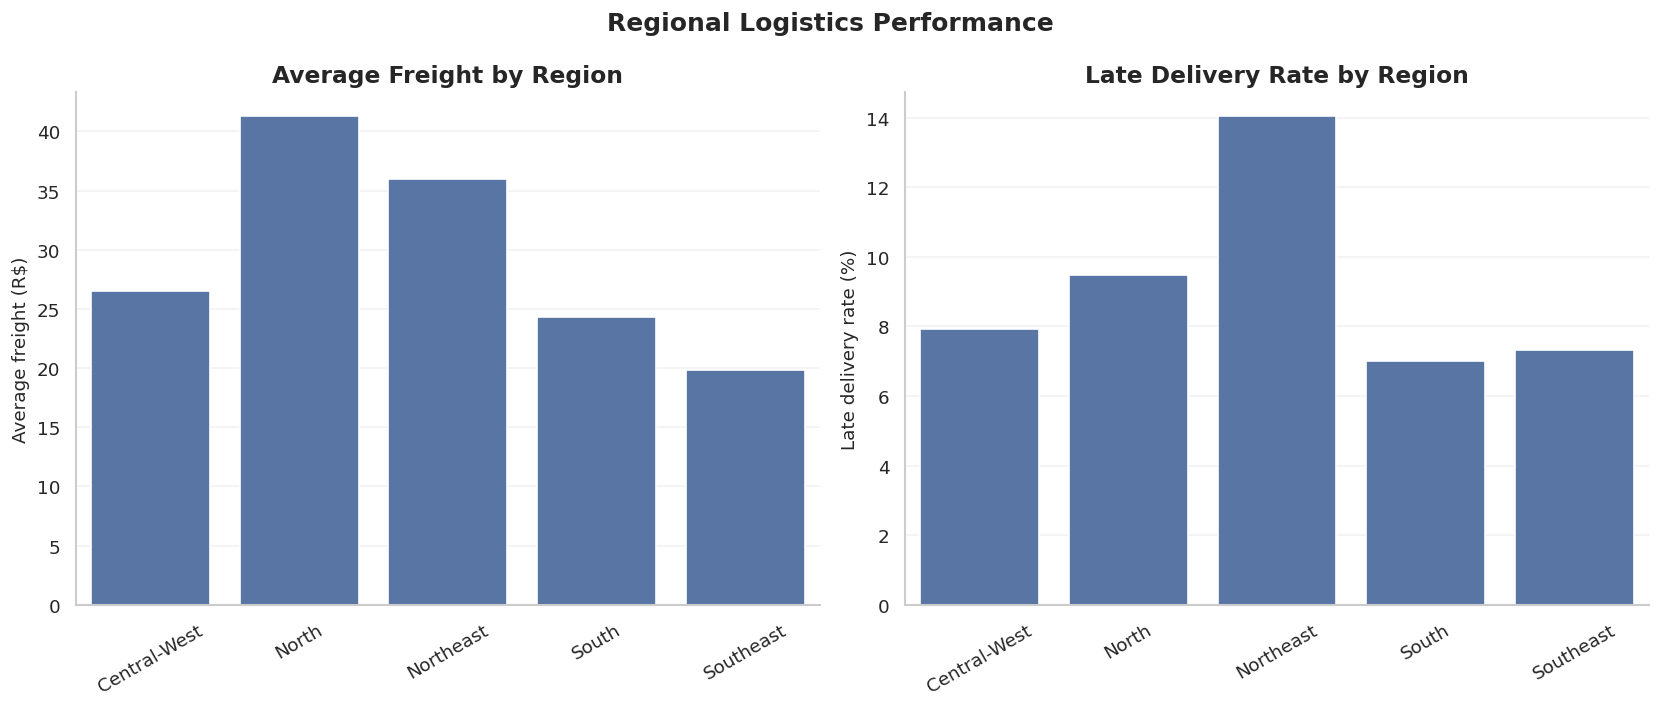

         region  average_freight  delivered_orders  late_orders  \
0  Central-West            26.48              5624          446   
1         North            41.29              1796          170   
2     Northeast            35.95              9044         1270   
3         South            24.36             13814          966   
4     Southeast            19.84             66200         4848   

   late_delivery_rate  
0                7.93  
1                9.47  
2               14.04  
3                6.99  
4                7.32  


In [ ]:
# Compare average freight cost and late delivery rate across Brazilian regions.
region_map = {
    "N": "North",
    "NE": "Northeast",
    "CO": "Central-West",
    "SE": "Southeast",
    "S": "South"
}

region_chart_data = (
    analysis_data["orders"]
    .merge(
        analysis_data["customers"][["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .merge(
        order_freight[["order_id", "freight_value"]],
        on="order_id",
        how="inner"
    )
)

region_chart_data = region_chart_data[
    region_chart_data["order_status"] == "delivered"
].copy()

region_chart_data["region"] = region_chart_data["customer_state"].map(
    lambda state: (
        "North" if state in ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]
        else "Northeast" if state in ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
        else "Central-West" if state in ["DF", "GO", "MT", "MS"]
        else "Southeast" if state in ["ES", "MG", "RJ", "SP"]
        else "South"
    )
)

region_chart_data = region_chart_data.merge(
    delivery_reviews[["order_id", "delivery_status"]],
    on="order_id",
    how="left"
)

region_performance = (
    region_chart_data
    .groupby("region")
    .agg(
        average_freight=("freight_value", "mean"),
        delivered_orders=("order_id", "nunique"),
        late_orders=("delivery_status", lambda x: (x == "Late").sum())
    )
    .reset_index()
)

region_performance["late_delivery_rate"] = (
    region_performance["late_orders"] / region_performance["delivered_orders"] * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    data=region_performance,
    x="region",
    y="average_freight",
    ax=axes[0]
)
axes[0].set_title("Average Freight by Region")
axes[0].set_xlabel("")
axes[0].set_ylabel("Average freight (R$)")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=region_performance,
    x="region",
    y="late_delivery_rate",
    ax=axes[1]
)
axes[1].set_title("Late Delivery Rate by Region")
axes[1].set_xlabel("")
axes[1].set_ylabel("Late delivery rate (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.suptitle("Regional Logistics Performance", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

print(region_performance.round(2))

In [ ]:
# Create the report destination folder and save the Python findings document.
import os

project_folder = "/content/drive/MyDrive/Olist"
os.makedirs(project_folder, exist_ok=True)

report_path = os.path.join(project_folder, "Python_Analysis_Findings.md")

with open(report_path, "w", encoding="utf-8") as report_file:
    report_file.write(python_report)

print("Python findings report saved successfully.")
print("Location:", report_path)

Python findings report saved successfully.
Location: /content/drive/MyDrive/Olist/Python_Analysis_Findings.md


In [ ]:
# Python analysis findings report.
python_report = """# Olist E-commerce Analytics — Python Analysis

## 1. Project Overview
Python was used to analyse Olist e-commerce transactions, customer purchasing behaviour, product performance, customer reviews, and regional logistics.

The analysis uses the original Olist dataset. No simulated business or customer records were introduced.

## 2. Business Performance
- November 2017 recorded the highest delivered order volume, with 7,289 orders.
- May 2018 recorded the highest monthly merchandise sales, at R$977,544.69.
- Average merchandise value per delivered order was R$137.04.
- Median merchandise value per delivered order was R$86.57.
- The order-value distribution was strongly right-skewed, indicating a high-value order tail.
- September and October 2018 have incomplete observation periods and should not be interpreted as a full-period sales decline.

## 3. Freight Analysis
- Average freight per delivered order was R$22.79.
- Average merchandise value was R$137.04.
- Freight exceeded merchandise value in 3,075 orders (3.19%).
- The North and Northeast had the highest regional average freight costs.

## 4. Customer Reviews
- 57.78% of reviews received 5 stars.
- 77.07% received 4 or 5 stars.
- 14.69% received 1 or 2 stars.
- Late deliveries were associated with substantially lower average review scores: 2.57 compared with 4.29 for on-time deliveries.
- This is an association and does not establish causation.

## 5. Customer Segmentation
RFM analysis identified two broad customer groups:
- Repeat customers: 2,801 customers (approximately 3%), averaging R$260.05 in historical merchandise value.
- One-time customers: 90,557 customers (approximately 97%), averaging R$137.96 in historical merchandise value.
- Repeat customers had approximately 1.88 times the average historical merchandise value of one-time customers.

The segments describe historical behaviour and are not predictions of future customer value.

## 6. Statistical Analysis
A Mann Whitney U test compared historical merchandise value between one time and repeat customers.
- Rank-biserial effect size: 0.4944.
- P-value: below 0.001.
- The results indicate a meaningful difference in the distributions of historical customer value.
- Statistical association does not establish that repeat purchasing causes higher spending.

## 7. Product Category Performance
- Health & Beauty led merchandise sales at approximately R$1.23 million.
- Watches & Gifts followed at approximately R$1.17 million.
- Bed Bath & Table generated approximately R$1.02 million and had the highest order volume among these leading categories.
- Category sales and order volume should be evaluated together.

## 8. Geographic Performance
- São Paulo led state-level merchandise sales at approximately R$5.07 million.
- Rio de Janeiro followed at approximately R$1.76 million.
- Minas Gerais generated approximately R$1.55 million.
- São Paulo, Rio de Janeiro, and Minas Gerais together represented approximately 59.3% of total merchandise sales.

## 9. Regional Logistics
- North: average freight approximately R$41.35.
- Northeast: average freight approximately R$35.99.
- Central-West: average freight approximately R$26.49.
- South: average freight approximately R$24.35.
- Southeast: average freight approximately R$19.84.

Higher freight costs and late delivery rates identify regions for further logistics investigation.

## 10. Business Recommendations
1. Prioritise customer retention initiatives for the large one-time customer segment.
2. Protect sales performance in the Southeast while monitoring geographic concentration.
3. Review freight and delivery performance in the North and Northeast.
4. Investigate late deliveries because of their strong association with lower review scores.
5. Monitor leading product categories and identify opportunities to improve weaker category performance.
6. Evaluate seller concentration and customer experience together.

## 11. Limitations
- The analysis is based on historical Olist marketplace data.
- Historical customer value is not predictive customer lifetime value.
- RFM clusters describe observed purchasing behaviour, not future behaviour.
- Associations between delivery performance and reviews do not prove causation.
- The dataset does not contain marketing campaign assignments, acquisition channels, or randomised experiment results.
- The 2018 observation period ends before a complete year is available.

## 12. Visualisations
Charts are stored in the `Visualisations` folder:
- Monthly business performance
- Order value distribution
- Freight cost distribution
- Customer review distribution
- RFM customer segment comparison
- One-time versus repeat customer value
- Product category performance
- State-level performance
- Regional logistics performance
"""

report_path = os.path.join(
    "/content/drive/MyDrive/Olist",
    "Python_Analysis_Findings.md"
)

with open(report_path, "w", encoding="utf-8") as report_file:
    report_file.write(python_report)

print("Python findings report saved:")
print(report_path)

Python findings report saved:
/content/drive/MyDrive/Olist/Python_Analysis_Findings.md
